# Digital-Platform Relative Strength — U.S. Digital Advertising & Streaming Services

**Reproduced retrospective price-return pilot; NOT PIT, NOT verified total returns, NOT investable equity alpha.**

Independent paper with saved computed results; 2018–2019 Plotly six-stock frozen demonstration sample.

## 01. Abstract

We ask whether a **predeclared, business-exposure-weighted eight-week relative-price-strength signal** improves forecasts of subsequent four-week benchmark-adjusted **price changes** for four digital-advertising/streaming-related U.S. public companies (GOOG, AMZN, FB, NFLX), relative to a two-stock technology comparison basket (AAPL, MSFT). On 65 purged expanding-window origins, the controlled model RMSE was **6.9437 percentage points**, versus **7.0143** with the new factor: a **-0.0706 pp** change (negative means deterioration). The factor does not pass the uncertainty, cross-sectional rank, and robustness tests. This is a deliberately narrow retrospective **price** panel, not a verified total-return or historical point-in-time equity-alpha backtest.

In [1]:
from pathlib import Path
import json,hashlib,subprocess,sys
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from analysis import (CORE,CONTROL,EXPOSURE,load_prices,panel,walk_forward,scorecard,
                      paired_improvement,rank_diagnostics,fast_placebo,moving_block_bootstrap,
                      fast_exposure_sensitivity,regime_table,FastRefit)
ROOT=Path.cwd()
summary=json.loads((ROOT/'results'/'summary.json').read_text())
print('Snapshot:',summary['n_raw_weeks'],'weekly rows | OOS:',summary['n_oos_origins'],'origins |',summary['status'])

Snapshot: 105 weekly rows | OOS: 65 origins | REPRODUCED RETROSPECTIVE PRICE-RETURN PILOT — NOT PIT / NOT TOTAL RETURN / NOT INVESTABLE ALPHA


In [2]:
print('Primary OOS result: control RMSE',round(summary['control_rmse_pp'],4),
      'augmented RMSE',round(summary['augmented_rmse_pp'],4),
      'improvement',round(summary['improvement_pp'],4),'percentage points')

Primary OOS result: control RMSE 6.9437 augmented RMSE 7.0143 improvement -0.0706 percentage points


## 02. Research Design & Hypotheses

**Primary question:** Does exposure-weighted relative momentum at weekly close *t* forecast stock *i*'s four-week price return above an AAPL/MSFT technology comparison basket, beyond a train-only linear control model?

- **H1:** The fixed eight-week exposure-weighted signal improves four-week OOS RMSE over historical mean and simple momentum baselines.
- **H2:** The signal improves a multivariate Ridge control after four-week purge, and survives block-aware 1,000-draw feature placebo and 2,000-draw paired block bootstrap.
- **H3:** Improvement survives alternative horizons, a one-week information delay, leave-one-company-out, and 1,000 plausible analyst-weight perturbations.
- **Null:** Conditional predictive information is zero; an apparent spread can be chance, concentration, or regime artifact.

The **counterthesis** is that an eight-week return signal is mostly a nonlinear re-expression of four-week momentum already in the controls; technology factor rotations and retrospective name selection dominate any industry mechanism. Failure means no robust incremental gain over the strongest simple baseline and zero-spanning bootstrap interval.

In [3]:
hypotheses=pd.DataFrame({'hypothesis':['H1','H2','H3','Null'],
'predeclared_test':['beats mean and momentum','beats multivariate Ridge + bootstrap and block shuffle',
'leave-one-company-out, horizons, 1-week lag, exposure perturbations','no conditional incremental predictive information']})
display(hypotheses)

,hypothesis,predeclared_test
0,H1,beats mean and momentum
1,H2,beats multivariate Ridge + bootstrap and block...
2,H3,"leave-one-company-out, horizons, 1-week lag, e..."
3,Null,no conditional incremental predictive information


In [4]:
print('Failure standard: no OOS gain vs strongest simple baseline, bootstrap includes zero, and regime instability.');print('Selection caveat: the 2018–2019 universe was not chosen prospectively.')

Failure standard: no OOS gain vs strongest simple baseline, bootstrap includes zero, and regime instability.
Selection caveat: the 2018–2019 universe was not chosen prospectively.


## 03. Industry Context

The target is **digital advertising and streaming services**, not all technology manufacturing. Alphabet (GOOG) and Facebook (FB) are advertising/platform-heavy; Netflix (NFLX) is streaming subscription-heavy; Amazon (AMZN) is mixed retail/cloud/media with a low analyst digital-media exposure. The six-ticker Plotly teaching basket was selected **after the period**, and AAPL/MSFT are technology comparators rather than a market index. No defensible historical industry market-size series was supplied by this source; **2018 market size and CAGR are UNKNOWN** and not estimated from stock prices. Pre-formation 2017 SEC 10-Ks provide qualitative business-line evidence, not precise revenue-weighted industry exposure.

In [5]:
exposure=pd.read_csv(ROOT/'data'/'exposure_map.csv');display(exposure[['ticker','role','analyst_digital_exposure','filing_date']])

,ticker,role,analyst_digital_exposure,filing_date
0,GOOG,core digital media/services (mixed exposure),0.95,2018-02-06
1,AMZN,core digital media/services (mixed exposure),0.30,2018-02-02
2,FB,core digital media/services (mixed exposure),1.00,2018-02-01
3,NFLX,core digital media/services (mixed exposure),0.85,2018-01-29
4,AAPL,two-stock technology comparison basket (NOT ma...,0.00,UNKNOWN
5,MSFT,two-stock technology comparison basket (NOT ma...,0.00,UNKNOWN


In [6]:
print('Company count:',len(exposure),'core digital-service names:',list(CORE),'comparison names:',list(CONTROL))
print('Industry market-size history: UNKNOWN — no market-size numbers inferred from this six-stock teaching sample.')

Company count: 6 core digital-service names: ['GOOG', 'AMZN', 'FB', 'NFLX'] comparison names: ['AAPL', 'MSFT']
Industry market-size history: UNKNOWN — no market-size numbers inferred from this six-stock teaching sample.


## 04. Data & Source Integrity

The frozen CSV is from [Plotly's documented sample dataset](https://plotly.com/python-api-reference/generated/plotly.express.data.html), with exact packaged [v6.5.2 dataset path](https://github.com/plotly/plotly.py/blob/v6.5.2/plotly/package_data/datasets/stocks.csv.gz). It has **105 strictly weekly **sample-grid** dates**, six positive normalized closing-price columns, 2018-01-01 to 2019-12-30. Input SHA-256 is recorded in `data/source_qa.md`. The first label (2018-01-01) falls on a U.S. market holiday, so the sample dates are not verified exchange close timestamps. The original exchange/vendor, adjustment factors, dividend treatment, sample creation date, historical price revisions and trading availability are **UNKNOWN**. Grade **B** applies only to the Plotly-distributed sample snapshot, **C** to unverified upstream market-data provenance, and **A** to SEC company filings. The `data/source_register.csv` contains exact URLs, observation periods, grades, filing dates where known, vintage limitations and permitted analytical roles.

In [7]:
sources=pd.read_csv(ROOT/'data'/'source_register.csv',keep_default_na=False)
display(sources[['source_id','grade','publisher','publication_date','period_start','period_end','vintage_revisions']])

,source_id,grade,publisher,publication_date,period_start,period_end,vintage_revisions
0,B01,B,Plotly,UNKNOWN,2018-01-01,2019-12-30,Original exchange/vendor and adjustment histor...
1,A_GOOG,A,SEC EDGAR,2018-02-06,2017-01-01,2017-12-31,2017 filing as indexed at SEC; subsequent amen...
2,A_FB,A,SEC EDGAR,2018-02-01,2017-01-01,2017-12-31,2017 filing as indexed at SEC; subsequent amen...
3,A_NFLX,A,SEC EDGAR,2018-01-29,2017-01-01,2017-12-31,2017 filing as indexed at SEC; subsequent amen...
4,A_AMZN,A,SEC EDGAR,2018-02-02,2017-01-01,2017-12-31,2017 filing as indexed at SEC; subsequent amen...
5,C01,C,Original market-data vendor UNKNOWN,UNKNOWN,2018-01-01,2019-12-30,UNKNOWN


In [8]:
prices=load_prices(ROOT/'data'/'plotly_stocks_2018_2019_frozen.csv')
print('shape:',prices.shape,'range:',prices.date.min(),prices.date.max(),
      'nulls:',int(prices.isna().sum().sum()),'weekly gaps:',prices.date.diff().dropna().dt.days.value_counts().to_dict())
print('raw SHA256:',hashlib.sha256((ROOT/'data'/'plotly_stocks_2018_2019_frozen.csv').read_bytes()).hexdigest())

shape: (105, 7) range: 2018-01-01 00:00:00 2019-12-30 00:00:00 nulls: 0 weekly gaps: {7: 104}
raw SHA256: b80a2e38aa02076ad977f89f9595853f5e69a0bd1e1d5726b761977101009a9e


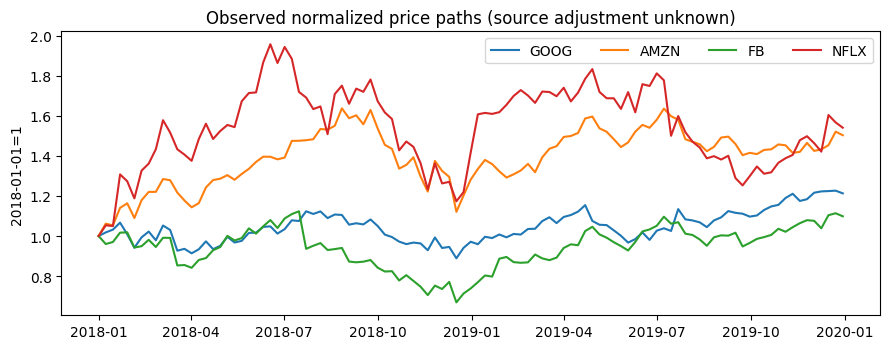

In [9]:
fig,ax=plt.subplots(figsize=(9,3.6))
for f in CORE:ax.plot(prices.date,prices[f],label=f)
ax.set_title('Observed normalized price paths (source adjustment unknown)');ax.set_ylabel('2018-01-01=1');ax.legend(ncol=4);plt.tight_layout();plt.show()

## 05. Point-in-Time Availability

At a weekly formation close *t*, only prices observed through *t* enter the signal. The four-week outcome uses *(t,t+4]* and training samples require **training origin + 4 ≤ test origin**; model means/scales and coefficients are recomputed only on the eligible training rows. All four 2017 SEC 10-K filings were publicly filed by **2018-02-06**, before evaluated OOS dates, but their **analyst exposure priors are reconstructed retrospectively**. Plotly's sample does not document original historical price timestamps, corporate-action adjustments or release vintages; mechanical date ordering is **not** a genuine PIT audit. The entire result remains a fixed-snapshot retrospective falsification pilot.

In [10]:
print('SEC 2017 filings last available:',sources.loc[sources.grade=='A','publication_date'].max())
print('Plotly historical price release/vintage:',sources.loc[sources.grade=='B','release_lag'].iloc[0])
print('UNKNOWN price adjustment and vendor: PIT claim explicitly prohibited.')

SEC 2017 filings last available: 2018-02-06
Plotly historical price release/vintage: UNKNOWN
UNKNOWN price adjustment and vendor: PIT claim explicitly prohibited.


In [11]:
p0=panel(prices);print('First raw formation:',p0.date.min(),'first OOS evaluated formation is later; target label is 4 weeks ahead.')
assert ((p0.target_date-p0.date).dt.days==28).all()

First raw formation: 2018-02-26 00:00:00 first OOS evaluated formation is later; target label is 4 weeks ahead.


## 06. Factor Construction

For company *i* at formation week *t*, with log normalized price \(p\) and equal-weight AAPL/MSFT log-price index \(b_t=(p_{AAPL,t}+p_{MSFT,t})/2\):

\[ M_{i,t}=100[(p_{i,t}-p_{i,t-8})-(b_t-b_{t-8})] \]
\[ F_{i,t}=w_i\tanh(M_{i,t}/20),\quad w_{GOOG,AMZN,FB,NFLX}=(.95,.30,1.00,.85). \]

The `20` scale, eight-week lookback and analyst weights are fixed, not fit on the target. The comparator index is an average of **log prices**, not a tradable rebalanced portfolio. The factor is price-derived; it is **not** independent evidence of advertising revenue, subscriptions or audience demand.

In [12]:
df=panel(prices);display(df[['date','firm','rel8','exposure','factor','y']].head(8).round(4))
print('Formula: factor_i,t = exposure_i * tanh((8-week stock log-return - 8-week comparator log-return)*100/20)')

,date,firm,rel8,exposure,factor,y
0,2018-02-26,GOOG,-5.1642,0.95,-0.2400,-1.0496
1,2018-02-26,AMZN,16.9050,0.30,0.2066,-0.1735
2,2018-02-26,FB,-8.6573,1.00,-0.4077,-6.5971
3,2018-02-26,NFLX,32.9949,0.85,0.7895,1.5054
4,2018-03-05,GOOG,-1.2285,0.95,-0.0583,-7.4330
5,2018-03-05,AMZN,14.4971,0.30,0.1860,-4.9412
6,2018-03-05,FB,-1.3247,1.00,-0.0661,-9.6971
7,2018-03-05,NFLX,35.8849,0.85,0.8043,-7.0430


Formula: factor_i,t = exposure_i * tanh((8-week stock log-return - 8-week comparator log-return)*100/20)


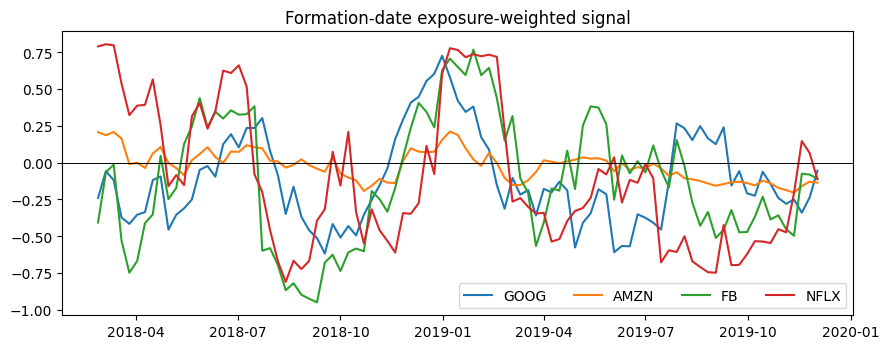

In [13]:
fig,ax=plt.subplots(figsize=(9,3.6))
for f in CORE:ax.plot(df.loc[df.firm==f,'date'],df.loc[df.firm==f,'factor'],label=f)
ax.axhline(0,color='black',linewidth=.7);ax.set_title('Formation-date exposure-weighted signal');ax.legend(ncol=4);plt.tight_layout();plt.show()

In [14]:
print('Fixed factor scales and weights:',EXPOSURE,'; factor uses no future target or full-sample standardization.')
assert all(np.allclose(df.loc[df.firm==f,'factor'],w*np.tanh(df.loc[df.firm==f,'rel8']/20)) for f,w in EXPOSURE.items())

Fixed factor scales and weights: {'GOOG': 0.95, 'AMZN': 0.3, 'FB': 1.0, 'NFLX': 0.85} ; factor uses no future target or full-sample standardization.


## 07. Exposure & Transmission

The pre-evaluation SEC evidence is [Alphabet 2017 10-K](https://www.sec.gov/Archives/edgar/data/1652044/000165204418000007/0001652044-18-000007-index.htm), [Facebook 2017 10-K](https://www.sec.gov/Archives/edgar/data/1326801/000132680118000009/0001326801-18-000009-index.html), [Netflix 2017 10-K](https://www.sec.gov/Archives/edgar/data/1065280/000106528018000069/0001065280-18-000069-index.htm) and [Amazon 2017 10-K](https://www.sec.gov/Archives/edgar/data/1018724/000101872418000005/0001018724-18-000005-index.htm). These filings establish business categories; the four weights are **analyst scenario priors**, not exact audited segment shares. The hypothesized channel is platform sentiment and demand anticipation → relative stock-price momentum → subsequent relative price changes, with major confounding from market beta, earnings surprises and rotation. `data/exposure_map.csv` preserves each filing URL/date and mapping rationale. There is no independent 2018–2019 fundamental outcome panel; 2017 filings are **descriptive only**, and no fundamental-lead conclusion is made.

In [15]:
display(exposure.loc[exposure.ticker.isin(CORE),['ticker','analyst_digital_exposure','filing_date','description']])

,ticker,analyst_digital_exposure,filing_date,description
0,GOOG,0.95,2018-02-06,Alphabet 2017 Form 10-K; advertising/search an...
1,AMZN,0.30,2018-02-02,Amazon 2017 Form 10-K; retail/cloud with parti...
2,FB,1.00,2018-02-01,Facebook 2017 Form 10-K; advertising/social pl...
3,NFLX,0.85,2018-01-29,Netflix 2017 Form 10-K; streaming subscriptions


In [16]:
print('Fundamental outcomes (2018-2019 revenue/EPS): NOT COLLECTED. 2017 SEC filings are qualitative exposure evidence only.')
print('No exact revenue-exposure weights, no firm-level independent demand outcome, no verified security total returns.')

Fundamental outcomes (2018-2019 revenue/EPS): NOT COLLECTED. 2017 SEC filings are qualitative exposure evidence only.
No exact revenue-exposure weights, no firm-level independent demand outcome, no verified security total returns.


## 08. Outcomes & Baselines

The outcome is \(Y_{i,t}=100[(p_{i,t+4}-p_{i,t})-(b_{t+4}-b_t)]\) **percentage points of log-price change**. It is **not total shareholder return**, and AAPL/MSFT is **not the S&P 500**. Models on identical OOS origins: expanding historical mean; last four-week relative return persistence; raw eight-week momentum; factor-only Ridge; controlled Ridge (lag4, lag1, four-week volatility, benchmark eight-week momentum, company fixed dummies); augmented Ridge (+factor). Ridge penalty is fixed at 10, with train-only z-scores and unpenalized intercept. Expanding evaluation has **65** origins × four stocks = **260** correlated security-week predictions; four-week labels overlap, so effective independent temporal information is far smaller than 260.

In [17]:
print('Target: 4-week log price change of core firm minus average 4-week AAPL/MSFT log price change; unit = percentage points.')
print('Train purge: origin_train + 4 <= origin_test; train-only scaling and coefficients.');print('Raw panel rows:',len(df))

Target: 4-week log price change of core firm minus average 4-week AAPL/MSFT log price change; unit = percentage points.
Train purge: origin_train + 4 <= origin_test; train-only scaling and coefficients.
Raw panel rows: 372


In [18]:
oos=walk_forward(df)
print('Model comparison observations:',oos.groupby('model').size().to_dict());print('OOS origins:',oos.t.nunique())
display(oos[['date','firm','model','train_origins','y','prediction']].head(8).round(3))

Model comparison observations: {'augmented': 260, 'control': 260, 'factor_only': 260, 'mean': 260, 'momentum': 260, 'persistence': 260}
OOS origins: 65


,date,firm,model,train_origins,y,prediction
0,2018-09-10,AMZN,mean,25,-7.577,-1.628
1,2018-09-10,FB,mean,25,-3.338,-1.628
2,2018-09-10,GOOG,mean,25,-3.381,-1.628
3,2018-09-10,NFLX,mean,25,-5.011,-1.628
4,2018-09-10,AMZN,persistence,25,-7.577,0.528
5,2018-09-10,FB,persistence,25,-3.338,-10.873
6,2018-09-10,GOOG,persistence,25,-3.381,-6.435
7,2018-09-10,NFLX,persistence,25,-5.011,10.009


In [19]:
display(scorecard(oos).round(4))
print('Persistence is a direct last-4-week return forecast; momentum is raw 8-week relative return, not fitted.')

,model,n_predictions,n_origins,rmse_pp,mae_pp,direction_accuracy
3,mean,260,65,6.6272,4.8347,0.6462
2,factor_only,260,65,6.7417,4.9159,0.6346
1,control,260,65,6.9437,5.2570,0.6000
0,augmented,260,65,7.0143,5.3034,0.5269
5,persistence,260,65,8.5029,6.4144,0.5769
4,momentum,260,65,11.7065,8.9806,0.5962


Persistence is a direct last-4-week return forecast; momentum is raw 8-week relative return, not fitted.


## 09. Empirical Findings

| Model | OOS predictions | RMSE (pp) | MAE (pp) | Direction accuracy |
|:--|--:|--:|--:|--:|
| mean | 260 | 6.6272 | 4.8347 | 0.646 |
| factor_only | 260 | 6.7417 | 4.9159 | 0.635 |
| control | 260 | 6.9437 | 5.2570 | 0.600 |
| augmented | 260 | 7.0143 | 5.3034 | 0.527 |
| persistence | 260 | 8.5029 | 6.4144 | 0.577 |
| momentum | 260 | 11.7065 | 8.9806 | 0.596 |

Control-minus-augmented RMSE is **-0.0706 pp** (negative = factor worsens). The augmented forecast rank IC averages **-0.160** across only four stocks per week; the top-minus-bottom realized benchmark-adjusted price-change spread averages **-1.509 pp** over overlapping four-week windows. Deducting a purely illustrative **20 basis point round-trip** gives **-1.709 pp**, **not** a backtested portfolio net return because turnover, rebalancing, dividends, financing, slippage and borrow are unverified. Figures 01–06 show raw paths, factor, outcome, RMSE, loss accumulation and IC.

In [20]:
sc=scorecard(oos);display(sc[['model','n_origins','n_predictions','rmse_pp','mae_pp','direction_accuracy']].round(4))
print('Control-minus-augmented RMSE:',round(paired_improvement(oos),6),'pp; negative = worse.')

,model,n_origins,n_predictions,rmse_pp,mae_pp,direction_accuracy
3,mean,65,260,6.6272,4.8347,0.6462
2,factor_only,65,260,6.7417,4.9159,0.6346
1,control,65,260,6.9437,5.2570,0.6000
0,augmented,65,260,7.0143,5.3034,0.5269
5,persistence,65,260,8.5029,6.4144,0.5769
4,momentum,65,260,11.7065,8.9806,0.5962


Control-minus-augmented RMSE: -0.070594 pp; negative = worse.


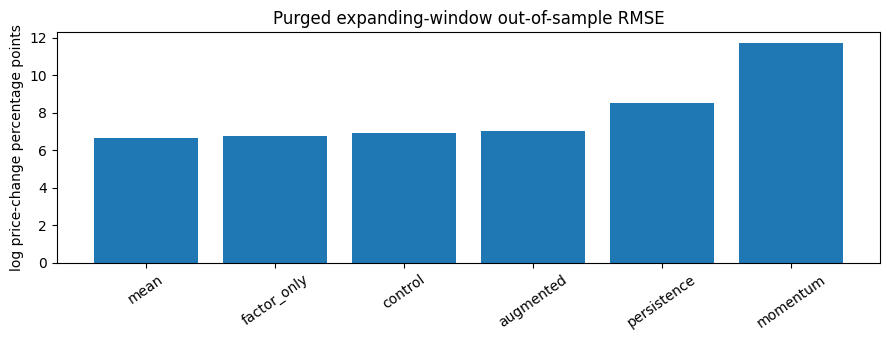

In [21]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.bar(sc.model,sc.rmse_pp);ax.tick_params(axis='x',rotation=35)
ax.set_title('Purged expanding-window out-of-sample RMSE');ax.set_ylabel('log price-change percentage points');plt.tight_layout();plt.show()

In [22]:
ic=rank_diagnostics(oos);print('Weekly mean rank IC:',round(ic.rank_ic.mean(),4),'mean top-bottom price spread:',round(ic.spread_pp.mean(),4),'pp')
display(ic[['date','rank_ic','spread_pp','long','short']].head(7).round(3))

Weekly mean rank IC: -0.16 mean top-bottom price spread: -1.5088 pp


,date,rank_ic,spread_pp,long,short
0,2018-09-10,0.4,2.565,NFLX,AMZN
1,2018-09-17,-0.8,-2.621,NFLX,FB
2,2018-09-24,0.4,1.555,GOOG,FB
3,2018-10-01,-0.8,-8.274,NFLX,FB
4,2018-10-08,1.0,7.199,GOOG,NFLX
5,2018-10-15,-0.4,-5.143,NFLX,FB
6,2018-10-22,-0.4,-4.855,NFLX,FB


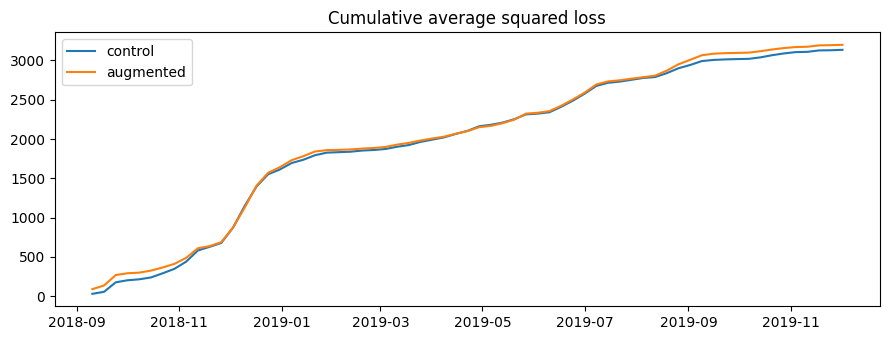

In [23]:
g=oos[oos.model.isin(['control','augmented'])].groupby(['date','model']).error.apply(lambda x:np.mean(x*x)).unstack()
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(g.index,g.control.cumsum(),label='control');ax.plot(g.index,g.augmented.cumsum(),label='augmented')
ax.set_title('Cumulative average squared loss');ax.legend();plt.tight_layout();plt.show()

## 10. Robustness & Placebos

A **1,000-refit** within-firm **four-week contiguous block-shuffle** of factor histories yields an exploratory upper-tail fraction **0.5405** for RMSE improvement; **not an exact p-value**, because overlapping targets and nonstationarity invalidate unconditional exchangeability. A **2,000-draw paired four-week moving-block bootstrap** gives a 95% improvement interval **[-0.3527, +0.1911] pp**, including zero. Under **1,000 fixed-prior exposure perturbations**, the fraction of improved forecasts is **0.000**. Leave-one-company-out (retrain/evaluate on the remaining three companies) tests concentration:

| Excluded company | Remaining-universe predictions/model | Improvement (pp) |
|:--|--:|--:|
| GOOG | 195 | -0.0849 |
| AMZN | 195 | -0.0491 |
| FB | 195 | -0.0169 |
| NFLX | 195 | -0.1018 |

Ablations and 40-week rolling training are saved in `results/ablations.csv` and `results/rolling.csv`; rolling improvement is **-0.3995 pp**. All 1,000 + 2,000 + 1,000 draw-level results are committed.

In [24]:
place=fast_placebo(df,n=1000,seed=20261028)
archive=pd.read_csv(ROOT/'results'/'placebo.csv')
assert np.allclose(place.rmse_improvement_pp,archive.rmse_improvement_pp)
actual=paired_improvement(oos);tail=(1+(place.rmse_improvement_pp>=actual).sum())/(len(place)+1)
print('1,000 refitted four-week-block shuffles; exploratory tail fraction:',round(tail,6),'(NOT exact p-value)')

1,000 refitted four-week-block shuffles; exploratory tail fraction: 0.54046 (NOT exact p-value)


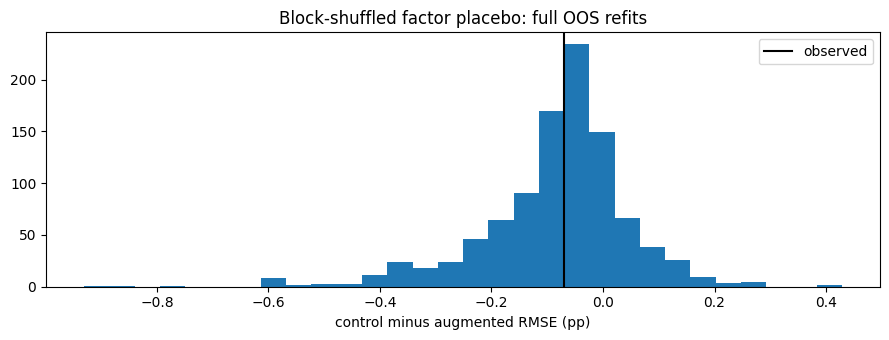

In [25]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.hist(place.rmse_improvement_pp,bins=30);ax.axvline(actual,color='black',label='observed')
ax.set_title('Block-shuffled factor placebo: full OOS refits');ax.set_xlabel('control minus augmented RMSE (pp)');ax.legend();plt.tight_layout();plt.show()

In [26]:
boot=moving_block_bootstrap(oos,n=2000,block=4,seed=20261029)
assert np.allclose(boot.rmse_improvement_pp,pd.read_csv(ROOT/'results'/'bootstrap.csv').rmse_improvement_pp)
ci=np.quantile(boot.rmse_improvement_pp,[.025,.975]);print('2,000 paired moving-block draws; 95% CI:',ci)

2,000 paired moving-block draws; 95% CI: [-0.35266635  0.19111831]


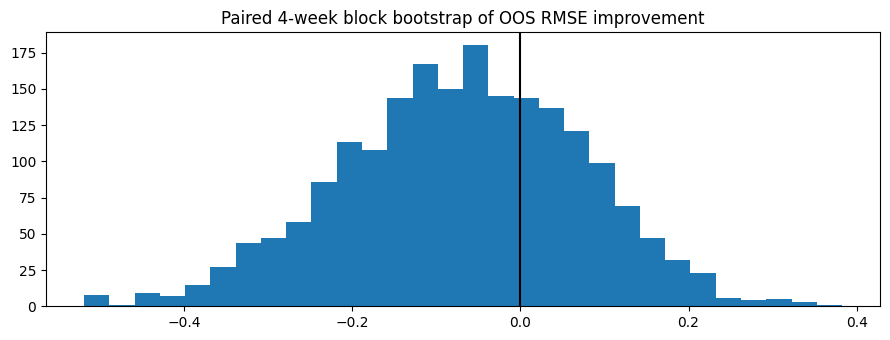

In [27]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.hist(boot.rmse_improvement_pp,bins=30);ax.axvline(0,color='black')
ax.set_title('Paired 4-week block bootstrap of OOS RMSE improvement');plt.tight_layout();plt.show()

1,000 exposure draws; share of RMSE improvements: 0.0


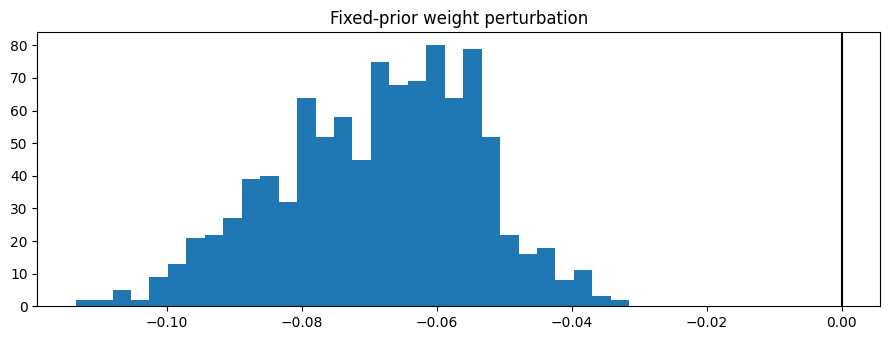

In [28]:
expo=fast_exposure_sensitivity(df,n=1000,seed=20261030)
assert np.allclose(expo.improvement_pp,pd.read_csv(ROOT/'results'/'exposure.csv').improvement_pp)
print('1,000 exposure draws; share of RMSE improvements:',round((expo.improvement_pp>0).mean(),4))
fig,ax=plt.subplots(figsize=(9,3.5));ax.hist(expo.improvement_pp,bins=30);ax.axvline(0,color='black');ax.set_title('Fixed-prior weight perturbation');plt.tight_layout();plt.show()

In [29]:
leave=pd.read_csv(ROOT/'results'/'leave_one_firm.csv');display(leave.round(4))
print('Leave-one-company-out retrains on and evaluates remaining 3; it is NOT an unseen-company holdout.')

,excluded,n_predictions_per_model,improvement_pp
0,GOOG,195,-0.0849
1,AMZN,195,-0.0491
2,FB,195,-0.0169
3,NFLX,195,-0.1018


Leave-one-company-out retrains on and evaluates remaining 3; it is NOT an unseen-company holdout.


In [30]:
ablate=pd.read_csv(ROOT/'results'/'ablations.csv');display(ablate.round(4))
print('40-week rolling controlled-minus-augmented RMSE:',round(summary['rolling_40wk_improvement_pp'],4))

,ablation,n_origins,rmse_improvement_vs_control_pp
0,no_vol,65,0.1320
1,no_bench,65,-0.1433
2,no_lag1,65,0.0038
3,no_dummies,65,0.1453


40-week rolling controlled-minus-augmented RMSE: -0.3995


## 11. Regime Sensitivity

| Calendar regime | OOS origins | RMSE improvement (pp) |
|:--|--:|--:|
| 2018 | 17 | -0.0873 |
| 2019H1 | 25 | +0.0462 |
| 2019H2 | 23 | -0.1958 |

Alternative horizons and conservative signal lags are calculated with separate purged training sets:

| Horizon (weeks) | Signal lag (weeks) | OOS origins | Improvement (pp) |
|--:|--:|--:|--:|
| 2 | 0 | 69 | -0.0511 |
| 2 | 1 | 68 | -0.0514 |
| 4 | 0 | 65 | -0.0706 |
| 4 | 1 | 64 | -0.0189 |
| 8 | 0 | 57 | +0.2414 |
| 8 | 1 | 56 | +0.2806 |

The 2018–2019 window is too short to represent rate, pandemic, and AI cycles; results are highly sensitive to market regime and sample choice.

,regime,origins,predictions_per_model,rmse_improvement_pp
0,2018,17,68,-0.0873
1,2019H1,25,100,0.0462
2,2019H2,23,92,-0.1958


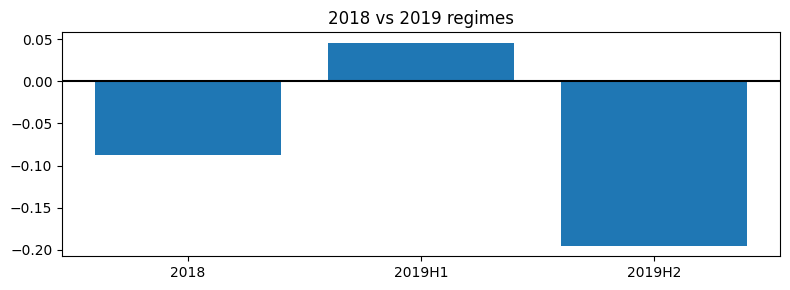

In [31]:
regimes=pd.read_csv(ROOT/'results'/'regimes.csv');display(regimes.round(4))
fig,ax=plt.subplots(figsize=(8,3));ax.bar(regimes.regime,regimes.rmse_improvement_pp);ax.axhline(0,color='black')
ax.set_title('2018 vs 2019 regimes');plt.tight_layout();plt.show()

,horizon_weeks,signal_lag_weeks,n_origins,improvement_pp
0,2,0,69,-0.0511
1,2,1,68,-0.0514
2,4,0,65,-0.0706
3,4,1,64,-0.0189
4,8,0,57,0.2414
5,8,1,56,0.2806


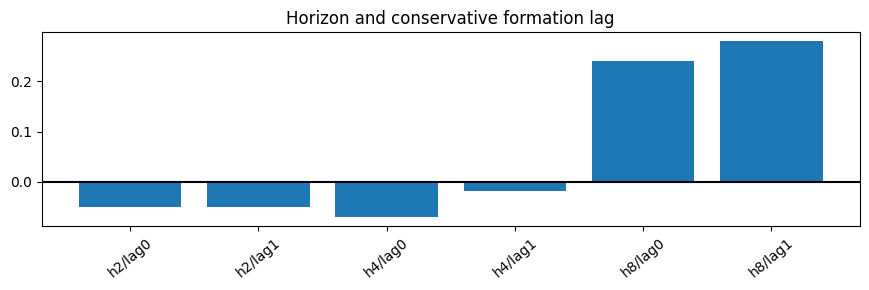

In [32]:
alternatives=pd.read_csv(ROOT/'results'/'alternatives.csv');display(alternatives.round(4))
fig,ax=plt.subplots(figsize=(9,3));ax.bar([f'h{r.horizon_weeks}/lag{r.signal_lag_weeks}' for r in alternatives.itertuples()],alternatives.improvement_pp)
ax.axhline(0,color='black');ax.tick_params(axis='x',rotation=40);ax.set_title('Horizon and conservative formation lag');plt.tight_layout();plt.show()

## 12. Bias Audit & Verdict

- **Historical PIT:** original price release/adjustment provenance UNKNOWN; no historical vendor tape.
- **Selection/survivorship:** six Plotly teaching tickers, retrospectively chosen four-company core; delistings and failed platforms excluded.
- **Leakage:** price features and train-only scaling avoid direct future-input leakage, but retrospective weights and source revisions remain unverified.
- **Temporal dependence:** overlapping four-week labels, strong shared market risk, only 65 test origins.
- **Multiple testing:** the predeclared main specification was tested with many robustness variants; no multiple-hypothesis adjusted alpha evidence.
- **Execution/costs:** normalized closing-price series, no total returns, borrow/turnover/market impact audit, and no real benchmark.
- **Fundamentals:** SEC filings used only for qualitative mapping, not independent 2018–2019 revenue/EPS outcome validation.

**Verdict: reject robust incremental predictive power.** The augmented model worsens OOS RMSE and has negative average cross-sectional rank IC. This is a reproduced, narrow, historical **price-return falsification pilot**, not an industry-demand lead, not PIT, and not investable equity alpha.

In [33]:
bias=pd.DataFrame({'risk':['Historical vendor PIT','Revisions/adjustments','Selection/survivorship','Overlapping labels','Multiple testing','Costs/borrow','Independent fundamentals'],
'finding':['UNKNOWN','UNKNOWN','Six-ticker selected demonstration basket','Four-week overlap; 65 origins','No adjusted discovery claim','20bp illustration only','Not collected']})
display(bias)

,risk,finding
0,Historical vendor PIT,UNKNOWN
1,Revisions/adjustments,UNKNOWN
2,Selection/survivorship,Six-ticker selected demonstration basket
3,Overlapping labels,Four-week overlap; 65 origins
4,Multiple testing,No adjusted discovery claim
5,Costs/borrow,20bp illustration only
6,Independent fundamentals,Not collected


In [34]:
gross=ic.spread_pp.mean();display(pd.DataFrame({'illustrative_roundtrip_cost_bps':[0,10,20,50,100],
'mean_top_minus_bottom_price_spread_pp':[gross-c/100 for c in [0,10,20,50,100]]}).round(3))
print('These are overlapping forecast-window spreads, NOT implementable net portfolio returns.')

,illustrative_roundtrip_cost_bps,mean_top_minus_bottom_price_spread_pp
0,0,-1.509
1,10,-1.609
2,20,-1.709
3,50,-2.009
4,100,-2.509


These are overlapping forecast-window spreads, NOT implementable net portfolio returns.


In [35]:
print('VERDICT:',summary['status']);print('Negative OOS incremental gain and negative rank IC, no PIT or total-return claim.')

VERDICT: REPRODUCED RETROSPECTIVE PRICE-RETURN PILOT — NOT PIT / NOT TOTAL RETURN / NOT INVESTABLE ALPHA
Negative OOS incremental gain and negative rank IC, no PIT or total-return claim.


## 13. Reproduction

From the study directory in a Python environment with declared packages:

```bash
python -m pip install -r requirements.txt
python run_analysis.py
python -m pytest -q tests
python execute_notebook.py
```

`run_analysis.py` saves full 1,000/2,000/1,000 draw distributions and 12 calculated PNG diagnostics. `execute_notebook.py` executes and saves the notebook with computed table/image outputs. `logs/` contains observed local execution, tests and clean-directory replay; GitHub CI structure checks are a **separate** claim and do not prove PIT or numeric reproduction. `data/plotly_stocks_2018_2019_frozen.csv` is committed; runtime extraction from Plotly is not required to reproduce the analysis.

In [36]:
print('Recorded artifacts:',len(list((ROOT/'figures').glob('*.png'))),'PNG figures;','1000/2000/1000 placebo/bootstrap/exposure draws')
print('Full numerical reproduction: python run_analysis.py | tests: python -m pytest -q tests | notebook: python execute_notebook.py')

Recorded artifacts: 12 PNG figures; 1000/2000/1000 placebo/bootstrap/exposure draws
Full numerical reproduction: python run_analysis.py | tests: python -m pytest -q tests | notebook: python execute_notebook.py


In [37]:
r=subprocess.run([sys.executable,'-m','pytest','-q','tests'],capture_output=True,text=True,check=False)
print('Observed tests from notebook kernel:');print(r.stdout[-1200:]);assert r.returncode==0,r.stderr

Observed tests from notebook kernel:
................                                                         [100%]
16 passed in 2.36s



## 14. Next-Stage Protocol

Acquire **vendor-verified daily unadjusted/adjusted prices, dividends, delisting histories and corporate-action timestamps**, plus the broad 2018-era digital-media universe; freeze actual original-release vintages. Obtain point-in-time quarterly company segment revenue, streaming subscribers and advertising demand from SEC filings with filing timestamps. Pre-register a monthly demand factor using **independent operating signals**, compare against sector ETF and a broad-market total-return benchmark, and enforce realistic turnover, borrow, slippage and false-discovery controls. Re-run a truly untouched post-2019 period before any alpha claim.

In [38]:
protocol=pd.DataFrame({'stage':['1 vendor tape','2 filing PIT','3 universe','4 model','5 trading audit','6 holdout'],
'deliverable':['daily prices, dividends, delistings, corporate actions','time-stamped digital ad/streaming operating metrics','all 2018 eligible public issuers','pre-registered non-price factor','market/sector total return, costs, borrow','untouched post-2019 evaluation']})
display(protocol)

,stage,deliverable
0,1 vendor tape,"daily prices, dividends, delistings, corporate..."
1,2 filing PIT,time-stamped digital ad/streaming operating me...
2,3 universe,all 2018 eligible public issuers
3,4 model,pre-registered non-price factor
4,5 trading audit,"market/sector total return, costs, borrow"
5,6 holdout,untouched post-2019 evaluation


## 15. Sources & Artifacts

- Grade B: [Plotly sample stock dataset](https://plotly.com/python-api-reference/generated/plotly.express.data.html) and [exact v6.5.2 packaged source](https://github.com/plotly/plotly.py/blob/v6.5.2/plotly/package_data/datasets/stocks.csv.gz); dataset original publication date **UNKNOWN**.
- Grade A: [GOOG 2017 SEC 10-K](https://www.sec.gov/Archives/edgar/data/1652044/000165204418000007/0001652044-18-000007-index.htm) (filed 2018-02-06), [FB 2017 SEC 10-K](https://www.sec.gov/Archives/edgar/data/1326801/000132680118000009/0001326801-18-000009-index.html) (filed 2018-02-01), [NFLX 2017 SEC 10-K](https://www.sec.gov/Archives/edgar/data/1065280/000106528018000069/0001065280-18-000069-index.htm) (filed 2018-01-29), [AMZN 2017 SEC 10-K](https://www.sec.gov/Archives/edgar/data/1018724/000101872418000005/0001018724-18-000005-index.htm) (filed 2018-02-02).
- Grade C: original market-price vendor, adjustment history and release vintage **UNKNOWN**.
- Frozen input `data/plotly_stocks_2018_2019_frozen.csv`; derived panel `data/derived_formation_panel.csv`; exposure mapping `data/exposure_map.csv`; full register `data/source_register.csv`; provenance audit `data/source_qa.md`.
- Full tables `results/*.csv`, numeric verdict `results/summary.json`, twelve diagnostics `figures/*.png`, notebook `research.ipynb`, source `analysis.py`, runner `run_analysis.py`, tests `tests/test_digital_media.py`, logs `logs/`.

In [39]:
display(sources[['source_id','grade','publisher','url','publication_date','vintage_revisions']])

,source_id,grade,publisher,url,publication_date,vintage_revisions
0,B01,B,Plotly,https://github.com/plotly/plotly.py/blob/v6.5....,UNKNOWN,Original exchange/vendor and adjustment histor...
1,A_GOOG,A,SEC EDGAR,https://www.sec.gov/Archives/edgar/data/165204...,2018-02-06,2017 filing as indexed at SEC; subsequent amen...
2,A_FB,A,SEC EDGAR,https://www.sec.gov/Archives/edgar/data/132680...,2018-02-01,2017 filing as indexed at SEC; subsequent amen...
3,A_NFLX,A,SEC EDGAR,https://www.sec.gov/Archives/edgar/data/106528...,2018-01-29,2017 filing as indexed at SEC; subsequent amen...
4,A_AMZN,A,SEC EDGAR,https://www.sec.gov/Archives/edgar/data/101872...,2018-02-02,2017 filing as indexed at SEC; subsequent amen...
5,C01,C,Original market-data vendor UNKNOWN,UNKNOWN,UNKNOWN,UNKNOWN


In [40]:
saved=json.loads((ROOT/'results'/'summary.json').read_text())
assert np.isclose(saved['improvement_pp'],paired_improvement(oos))
assert saved['n_oos_origins']==oos.t.nunique()
assert saved['publication_vintage']=='UNKNOWN' and saved['total_return_adjustment']=='UNKNOWN'
print('Saved outputs and current computed metrics agree. Final verdict: NEGATIVE / RETROSPECTIVE / NOT INVESTABLE.')

Saved outputs and current computed metrics agree. Final verdict: NEGATIVE / RETROSPECTIVE / NOT INVESTABLE.
